# 02 · The rule, developed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p05_when_to_stop/notebooks/02_the_rule.ipynb)

**Project 5 — When to stop.** Per cubic metre of permeate, a batch ended after V m³ costs

$$J(V) = \frac{F + E(V)}{V}$$

where E(V) is the energy spent so far and F the fixed cost of ending: draining the loop and paying for
its brine. J falls at first (F spreads over more water), then rises (each new m³ costs more energy).
At its minimum dJ/dV = 0, which works out to

$$\underbrace{E'(V)}_{\text{live cost of the next m}^3} \;=\; \underbrace{\frac{F + E(V)}{V}}_{\text{average cost so far}}$$

**Stop when the live cost of the next cubic metre reaches the average cost so far.** The live cost is
pump power ÷ permeate flow — a number the testbed already displays. No model, no search.

If the live cost climbs in a straight line, m = m₀ + sV, the stop has a closed form —
**V\* = √(2F/s)**, the square-root law of cleaning intervals and of order quantities.

**Data:** a public closed-circuit reverse-osmosis (CCRO) testbed record, "Foundational Control Methods for Water Treatment Systems — Online Actuator and Sensor Data", [doi:10.7481/1963162](https://doi.org/10.7481/1963162), CC BY 4.0: 881 batch files from June to October 2021. The notebooks read the tables committed in `results/` and a 0.8 MB excerpt of five batch files; the 351 MB of zips are needed only where a cell says so.

Script version: `step2_ccro_rule_dev.py` · record: `VALIDATION.md`, sections 2–3.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 5 pull request is merged, use "p05-when-to-stop"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P5 = ROOT / "projects" / "p05_when_to_stop"
RES = P5 / "results"
sys.path.insert(0, str(P5))          # the step scripts, for the helpers they define

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, TEAL = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#0f7c8c"

def load(name):
    """A committed result file from projects/p05_when_to_stop/results/."""
    return json.loads((RES / name).read_text())

## 1. The cost curve of one batch

Batch 11's brine is drained at the start of batch 12's file; that drain sets its fixed cost. For any
point of the batch we can ask what it *would* have cost had it ended there — exactly, because where a
batch is stopped does not change its path up to that point.

Text(0.0, 1.0, 'each dot: the best end at that brine price')

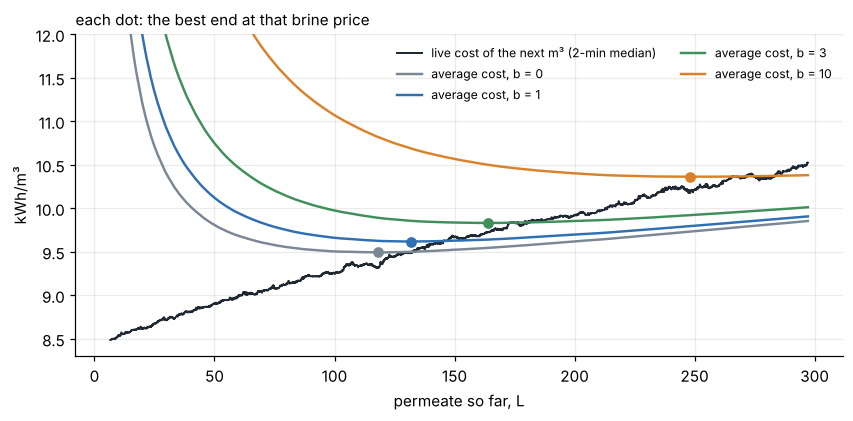

In [2]:
from chemai.config import CCROConfig
from chemai.features.ccro_batches import batch_curve, batch_table, cost_curve, phase_of
from chemai.models.stopping import rolling_median, marginal_equals_average
cfg = CCROConfig()
x = pd.read_parquet(RES / "excerpt_batches.parquet")
for c in ["permeate_conductivity_us_per_cm", "set_low_rej_cond_ms_per_cm"]:
    x[c] = np.nan
bo = x[x.dataset == "dataset6"]
row = batch_table(bo).set_index("seq").loc[11]
curve = batch_curve(bo[bo.seq == 11], cfg)
filt = curve.phase.to_numpy() == "filt"
t, V = curve.t_s.to_numpy(), curve.V_m3.to_numpy() * 1000
live = rolling_median(t, curve.live_kwh_m3.to_numpy(), cfg.live_window_s)
ok = filt & (curve.elapsed_min.to_numpy() >= 3)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(V[ok], live[ok], color=INK, lw=1.3, label="live cost of the next m³ (2-min median)")
for b, c in ((0, MUTED), (1, BLUE), (3, GREEN), (10, ORANGE)):
    J = cost_curve(curve, row.own_drain_kwh, row.brine_l, b)
    i = np.where(ok)[0][np.nanargmin(J[ok])]
    ax.plot(V[ok], J[ok], color=c, lw=1.6, label=f"average cost, b = {b}")
    ax.plot(V[i], J[i], "o", color=c, ms=6)
ax.set_ylim(8.3, 12); ax.set_xlabel("permeate so far, L"); ax.set_ylabel("kWh/m³")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.set_title("each dot: the best end at that brine price", loc="left", fontsize=10)

Each average-cost curve has its minimum exactly where it meets the live-cost line — the rule, seen
on a real batch. The dearer the brine, the further out the meeting point: each dot sits to the right
of the one before. And the curves are **flat** near their minima: ending a few minutes early or late
costs almost nothing. Remember that when judging any optimiser.

## 2. The rule, as it would run live

Live, the rule knows only the past. It uses the drain *before* the batch (the one that opens its
file) as F, a 2-minute trailing median of the live cost, and no stop in the first 5 minutes.

In [3]:
for b in (0, 1, 3, 10):
    F_prior = row.prior_drain_kwh + b * row.prior_brine_l / 1000
    d = marginal_equals_average(t, curve.live_kwh_m3.to_numpy(), curve.E_kwh.to_numpy(), curve.V_m3.to_numpy(),
                                F_prior, cfg.live_window_s, min_elapsed_s=300, allowed=filt)
    J = cost_curve(curve, row.own_drain_kwh, row.brine_l, b)
    best = np.where(ok)[0][np.nanargmin(J[ok])]
    stop = d.index if d.index is not None else np.where(filt)[0][-1]
    print(f"b = {b:>2}: rule stops at {curve.c_ms_cm.iat[stop]:5.1f} mS/cm, {V[stop]:5.0f} L;"
          f"  best {curve.c_ms_cm.iat[best]:5.1f} mS/cm;  cost above the best {100*(J[stop]/J[best]-1):.3f} %")

b =  0: rule stops at  16.6 mS/cm,   127 L;  best  15.9 mS/cm;  cost above the best 0.035 %
b =  1: rule stops at  17.8 mS/cm,   141 L;  best  17.1 mS/cm;  cost above the best 0.033 %
b =  3: rule stops at  20.0 mS/cm,   172 L;  best  19.4 mS/cm;  cost above the best 0.027 %
b = 10: rule stops at  25.9 mS/cm,   262 L;  best  25.1 mS/cm;  cost above the best 0.009 %


## 3. Why the rule is declared only for held setpoints

In the set-point-step experiments the operators stepped the flux up and down every few minutes to
identify the plant. When the flux drops, the live cost per m³ jumps — not because the batch got
dearer to continue, but because the pumps make less water. The rule cannot tell the difference.

Text(0.0, 1.0, 'a set-point-step batch: the live cost follows the flux, not the loop')

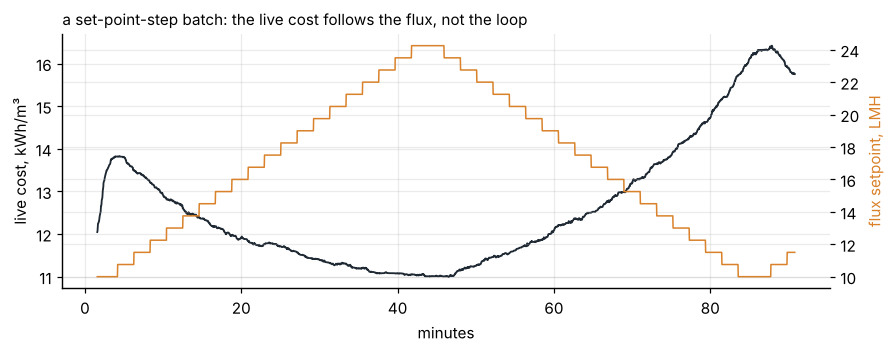

In [4]:
st = x[x.dataset == "dataset4"]
cs = batch_curve(st, cfg)
fs = cs.phase.to_numpy() == "filt"
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(cs.elapsed_min[fs], rolling_median(cs.t_s.to_numpy(), cs.live_kwh_m3.to_numpy(), 120)[fs], color=INK, lw=1.2)
ax2 = ax.twinx(); ax2.plot(cs.elapsed_min[fs], st[st.state.map(phase_of).isin(["startup", "stab", "filt"])]
                           .feed_pump_set_flux_lmh.to_numpy()[fs], color=ORANGE, lw=1)
ax.set_ylabel("live cost, kWh/m³"); ax2.set_ylabel("flux setpoint, LMH", color=ORANGE)
ax.set_xlabel("minutes"); ax.set_title("a set-point-step batch: the live cost follows the flux, not the loop", loc="left", fontsize=10)

So the rule is declared for batches whose flux and recirculation setpoints are held — all ESC and
BO batches. The MPC batches move their flows 18–66 times each and are left out.

## 4. What the development batches gave

`step2_ccro_rule_dev.py` ran the rule on every ESC and open-loop batch with held setpoints and its own
brine measured. A batch is *inside* when its own best end lies at least 5 minutes before the batch
actually ended — only then is the rule's regret exact.

In [5]:
dev = load("step2_ccro_rule_dev.json")
rows = []
for b, v in dev["rule_on_development"].items():
    rows.append({"b": b, "batches inside": v["batches_inside"], "rule median %": v["rule_regret_pct"]["median"],
                 "rule p90 %": v["rule_regret_pct"]["p90"], "controller's end median %": v["controller_regret_pct"]["median"],
                 "square-root forecast, median abs error %": v["sqrt_law"]["median_abs_error_pct"]})
pd.DataFrame(rows)

,b,batches inside,rule median %,rule p90 %,controller's end median %,"square-root forecast, median abs error %"
0,b=0,69,0.067,0.105,0.155,3.70
1,b=1,8,0.080,0.100,2.402,2.10
2,b=3,8,0.071,0.138,1.224,2.78
3,b=10,3,0.082,0.096,0.097,6.33


And a finding on the side, because the ESC batches are development data:

In [6]:
pd.DataFrame(dev["esc_audit"])[["exp", "b", "batches", "still_falling_at_end", "c_end_median"]]

,exp,b,batches,still_falling_at_end,c_end_median
0,Exp1,1.0,203,1.0,7.181
1,Exp2,10.0,57,1.0,10.486
2,Exp2_continued/Data,10.0,42,1.0,13.247
3,Exp3,10.0,278,1.0,15.416


**Every one of the 580 ESC batches ended while the live cost was still below the average** — the
cost was still falling. Look at one:

Text(0.0, 1.0, 'ESC Exp1 no. 40 ended at 6.9 mS/cm — the average was still falling')

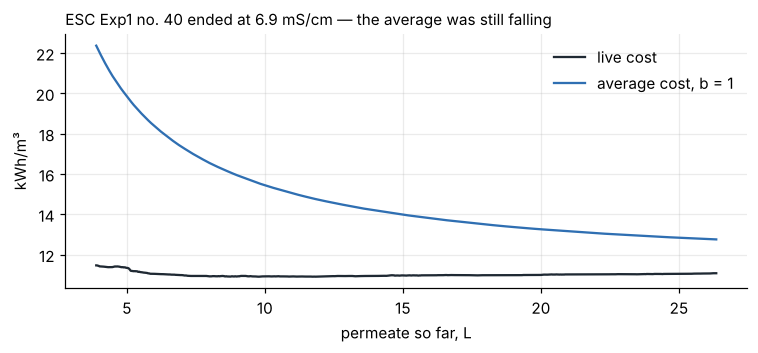

In [7]:
esc = x[x.dataset == "dataset3"]
er = batch_table(esc).set_index("seq").loc[40]
ce = batch_curve(esc[esc.seq == 40], cfg)
fe = ce.phase.to_numpy() == "filt"
Je = cost_curve(ce, er.own_drain_kwh, er.brine_l, 1.0)
me = rolling_median(ce.t_s.to_numpy(), ce.live_kwh_m3.to_numpy(), 120)
k = fe & (ce.elapsed_min.to_numpy() >= 2)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ce.V_m3[k] * 1000, me[k], color=INK, label="live cost"); ax.plot(ce.V_m3[k] * 1000, Je[k], color=BLUE, label="average cost, b = 1")
ax.set_xlabel("permeate so far, L"); ax.set_ylabel("kWh/m³"); ax.legend(frameon=False)
ax.set_title(f"ESC Exp1 no. 40 ended at {er.c_end:.1f} mS/cm — the average was still falling", loc="left", fontsize=10)

These settings — the 2-minute median, the 5-minute floor, the previous drain as F — were frozen in
`DECLARED_BEFORE_RUN_A.md`, committed and pushed **before** a single test batch was scored. The next
notebook is that test.